# Every sensor joined to every other

**Graph notebook 2 in `notebooks/graph/`.** Read `01_physics_fd001.ipynb` first: this notebook takes the same steps on a different graph, and uses its words — the table of zeros and ones, the rescaled table `Â`, mixing and transforming, reach.

## What this notebook is for

The paper's Table 11 reports its network "without physics prior", but never says what took the place of its hand-designed graph. This project's reading is a graph that joins every sensor to every other (assumption A-19): every pair is joined alike, so the graph says nothing about which sensors are related. This notebook shows what that graph does to the numbers, and finds that in this network it does more than remove the paper's knowledge. Every sensor receives the same average, and the network's prediction comes to depend on one number alone: the average of the 14 sensors' last readings.

## What it does not do

- **It does not train anything.** It loads the network seed 42 trained in a stored run, and reads all five seeds' results from that run.
- **It does not measure what this graph costs.** `04_comparison_fd001.ipynb` does, seed by seed against the paper's graph.
- **It does not repeat the paper's experiment.** What the paper put in its graph's place is unknown, and its network has a recurrent stage these runs do not.

## The notebook in one list

| # | Step | What goes in | What comes out |
|---|------|--------------|----------------|
| 1 | **Load** the stored network | the stored five-seed run of this graph | seed 42's network and its data, checked against the run |
| 2 | **Read** the table | the 14 x 14 table of zeros and ones | 91 edges, every pair of sensors |
| 3 | **Rescale** it | the same table | a table holding one value, 1/14, in every cell |
| 4 | **Run one graph layer by hand** | one real window and the trained layer's 32 learned numbers | 14 identical rows of 32 numbers |
| 5 | **Find what the prediction depends on** | the 100 test engines' windows | the evidence that the prediction is a function of one number |
| 6 | **Read the stored result** | the five seeds' scores | the mean and spread on the test engines and on the held-back engines |

## 1. Background

### Why every sensor joined

The assumptions log lists three readings of "without physics prior" (assumption A-19): every sensor joined to every other, no sensor joined to any other, or a graph built from the data. Joining none would stop the graph layers combining sensors at all, which the paper reports separately as its network "without GCN" — a GCN, a graph convolutional network, being the graph layers. A graph built from the data is `03_correlation_fd001.ipynb`. Joining every sensor is the reading this project takes as the paper's experiment, and the reason this notebook exists is that it changes more than the knowledge.

### What it does, on three sensors

The numbers are made up, as in `01_physics_fd001.ipynb`'s three-sensor example. Join all three sensors to each other. `A + I` is then all ones, every row total is 3, and every entry of `Â` is 1/3:

```
Â     = [[1/3, 1/3, 1/3],          H = [4, 1, -2]
         [1/3, 1/3, 1/3],
         [1/3, 1/3, 1/3]]          Â H = [(4 + 1 - 2) / 3] * 3 = [1, 1, 1]
```

Every sensor receives the same number, the average of all three. In the first notebook's example, where only `a`-`b` and `b`-`c` were joined, the three received 2.5, 1.0 and -0.5. Whatever `W` and ReLU do next, they do the same thing to three identical rows, so the three come out identical.

### Why the whole prediction then depends on one number

Follow the 14 sensors of this network through it, writing `m` for the average of their 14 last readings.

1. **Graph layer 1.** Every row of `Â` takes the same average, so every sensor gets `m`, and leaves the layer as the same 32 numbers, `ReLU(m W(1))`.
2. **Graph layers 2 and 3.** Each averages 14 identical rows, which gives that row back, and transforms it with the same table for every sensor. The rows stay identical. The graph layers hand on 14 copies of one row of 32 numbers; call it `r`. It was built from `m` and from learned numbers, and from nothing else.
3. **The first dense layer** multiplies each of the 448 numbers it receives by a learned weight of its own and adds the products up, once for each of its 128 outputs. Split one output's 448 weights into 14 blocks of 32, `W_1` to `W_14`, one per sensor. Since every sensor hands on the same `r`, that output is `W_1·r + W_2·r + ... + W_14·r`, which is `(W_1 + W_2 + ... + W_14)·r`: one block of summed weights times `r`. With made-up numbers, two blocks `W_1 = [1, 2]` and `W_2 = [3, -1]` and `r = [0.5, 1]`: `W_1·r + W_2·r = 2.5 + 0.5 = 3.0`, and `(W_1 + W_2)·r = [4, 1]·[0.5, 1] = 3.0`.

So everything after the graph layers is a function of `r`, and `r` is a function of `m`. **The prediction is a function of one number**, the average of the 14 last readings. Two windows whose last readings average the same must get the same prediction, however differently the readings are spread among the sensors. Step 5 tests exactly that on the trained network.

## 2. Setup

The imports, then the stored runs, chosen by the rule `notebooks/graph/README.md` gives: the newest commit at which all three graphs have a stored five-seed run of `config/fd001.yaml` that saved its trained networks, and the newest run of each graph at that commit. Every notebook in this folder chooses the same way, so all four read the same runs. If a run is missing, the cell stops and prints the commands that make them.

In [1]:
from __future__ import annotations

import logging
import sys
from dataclasses import replace
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The project's top folder is the nearest one above this notebook that holds
# pyproject.toml. Adding its src/ folder to Python's search path makes the
# package importable from a clone that was never installed.
PROJECT_ROOT = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "pyproject.toml").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

try:
    import torch
except ImportError as missing:
    raise ImportError(
        "This notebook loads a trained network, which needs PyTorch, and PyTorch is "
        'not installed. Install the project with  pip install -e ".[model]"'
    ) from missing

from thesis_gnn_rul_xai.config import load_config
from thesis_gnn_rul_xai.graph.adjacency import (
    adjacency_report,
    adjacency_to_frame,
    build_fully_connected_adjacency,
    normalize_adjacency,
)
from thesis_gnn_rul_xai.models import ModelConfig
from thesis_gnn_rul_xai.training import TrainingConfig, evaluate_model, find_runs, load_seed
from thesis_gnn_rul_xai.utils.logging_setup import configure_logging

configure_logging(logging.ERROR)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch     : {torch.__version__}")

Project root: D:\Main\University\Thesis\Code\Thesis GNN RUL XAI
PyTorch     : 2.13.0+cpu


In [2]:
config = load_config(PROJECT_ROOT / "config" / "fd001.yaml")
GRAPHS = ("physics", "complete", "correlation")
GRAPH = "complete"    # the graph this notebook shows
SEED = 42              # the network every worked example uses
COMMAND = "python scripts/train.py --config config/fd001.yaml --graph {} --seeds 5"
# The training settings a run records in its summary.json, at their default values.
TRAINING = {key: getattr(TrainingConfig(), key) for key in (
    "epochs", "batch_size", "learning_rate", "final_learning_rate", "early_stopping_patience")}


def stored_runs(kind: str) -> list:
    # Five seeds of config/fd001.yaml with only the graph changed, the trained
    # networks saved, the network sizes of the paper's Table 4, and the default
    # training settings.
    return [
        stored for stored in find_runs(
            preprocessing=replace(config, graph=kind), seeds=5, with_weights=True,
            split="varies_with_seed", early_stopping=True, lr_schedule="step",
            temporal_stage="last_cycle",
        )
        if stored.model_config == ModelConfig()
        and {key: stored.summary.get("training", {}).get(key) for key in TRAINING} == TRAINING
    ]


found = {kind: stored_runs(kind) for kind in GRAPHS}
shared = set.intersection(*({stored.summary["commit"] for stored in runs} for runs in found.values()))
if not shared:
    missing = [kind for kind, runs in found.items() if not runs]
    raise FileNotFoundError(
        ("reports/ holds no stored five-seed run, with its networks saved, for: "
         + ", ".join(missing) if missing
         else "The stored runs of the three graphs come from different commits.")
        + "\nFrom one committed state of the code, run\n\n"
        + "\n".join("    " + COMMAND.format(kind) for kind in GRAPHS)
        + "\n\nand run this notebook again."
    )

# The newest commit at which all three graphs were stored, and the newest run
# of each graph at that commit.
newest = {
    commit: max(stored.summary["finished_utc"] for runs in found.values()
                for stored in runs if stored.summary["commit"] == commit)
    for commit in shared
}
commit = max(shared, key=newest.get)
runs = {kind: [s for s in found[kind] if s.summary["commit"] == commit][-1] for kind in GRAPHS}
run = runs[GRAPH]

print(f"Commit of all three graphs' runs: {commit}")
for kind, stored in runs.items():
    print(f"  {kind:12s} {stored.name}")

Commit of all three graphs' runs: f386291-dirty
  physics      fd001_physics_row_cap_5seed_varsplit_cfgba82e3_f386291-dirty_20260914T150004Z
  complete     fd001_complete_row_cap_5seed_varsplit_cfgf21547_f386291-dirty_20260914T150527Z
  correlation  fd001_correlation_row_cap_5seed_varsplit_cfg7fdfce_f386291-dirty_20260914T150213Z


## 3. The trained network

### Step 1 — Load the stored network

**What.** Load the network that seed 42 trained in the run chosen above, from the `model.pt` saved beside it, and rebuild its data with the same seed.

**Why.** The worked examples below should show the graph and the layer a network of this project's reported runs actually used. A network trained here instead would be one seed and would record no commit.

**Check.** The loaded network must score the test engines exactly as the run recorded for seed 42, and the graph inside it must be the rescaled table the rebuilt data holds.

In [3]:
model, prepared = load_seed(run, SEED)
sensors = list(prepared.sensor_symbols)

recorded = float(run.results.set_index("seed").loc[SEED, "rmse"])
scored = evaluate_model(model, prepared.test)["rmse"]
same_network = bool(np.isclose(scored, recorded, rtol=0, atol=1e-6))
same_graph = bool(np.allclose(model.adjacency.numpy(), prepared.adjacency_normalized))
assert same_network and same_graph
print(f"OK  test RMSE {scored:.6f} cycles, as the run recorded for seed {SEED}.")
print("OK  The network's graph is the rescaled table of the rebuilt data.")

OK  test RMSE 18.820198 cycles, as the run recorded for seed 42.
OK  The network's graph is the rescaled table of the rebuilt data.


## 4. The graph, step by step

### Step 2 — Read the table

**What.** Print the table of zeros and ones the network's data was built with.

**Why.** It is the one thing that differs from the paper's graph in these runs.

**Check.** Every cell off the diagonal must be 1 and every cell on it 0: 14 x 13 / 2 = 91 edges, each sensor with 13 neighbours, every pair of sensors one edge apart.

In [4]:
raw = prepared.adjacency_raw          # NumPy array, shape (14, 14)
display(adjacency_to_frame(raw.astype(int), sensors))

report = adjacency_report(raw, sensors)
every_pair_joined = bool((raw == build_fully_connected_adjacency(len(sensors))[0]).all())
assert every_pair_joined and report["n_edges"] == 91 and report["diameter"] == 1
print(f"OK  {report['n_edges']} edges, every sensor joined to {set(report['degrees'].values())} others, "
      f"largest distance {report['diameter']} edge.")

,T24,T30,T50,P15,P30,Nf,Nc,Ps30,phi,NRf,BPR,htBleed,W31,W32
T24,0,1,1,1,1,1,1,1,1,1,1,1,1,1
T30,1,0,1,1,1,1,1,1,1,1,1,1,1,1
T50,1,1,0,1,1,1,1,1,1,1,1,1,1,1
P15,1,1,1,0,1,1,1,1,1,1,1,1,1,1
P30,1,1,1,1,0,1,1,1,1,1,1,1,1,1
Nf,1,1,1,1,1,0,1,1,1,1,1,1,1,1
Nc,1,1,1,1,1,1,0,1,1,1,1,1,1,1
Ps30,1,1,1,1,1,1,1,0,1,1,1,1,1,1
phi,1,1,1,1,1,1,1,1,0,1,1,1,1,1
NRf,1,1,1,1,1,1,1,1,1,0,1,1,1,1


OK  91 edges, every sensor joined to {13} others, largest distance 1 edge.


### Step 3 — Rescale it

**What.** Add 1 down the diagonal and divide every row by its total, as for the paper's graph. `A + I` is now all ones, every row total is 14, and every cell becomes 1/14.

**Why.** It is the table the network multiplies by.

**Check.** The table must hold one value only, 1/14, and be what `normalize_adjacency(raw, method="row")` gives. The cell also tries the other rescaling the paper's wording allows, which divides each entry by the square root of both sensors' row totals (assumption A-21).

In [5]:
a_hat = prepared.adjacency_normalized          # NumPy array, shape (14, 14)
values = np.unique(a_hat)
one_value = bool(len(values) == 1 and np.isclose(values[0], 1 / 14))
matches_function = bool(np.allclose(a_hat, normalize_adjacency(raw, method="row")))
assert one_value and matches_function
print(f"Every one of the 196 cells holds {values[0]:.6f}; 1/14 = {1 / 14:.6f}.")
n_different_rows = len(np.unique(np.round(a_hat.astype(float), 9), axis=0))
print(f"{n_different_rows} different row among the 14: every sensor takes the same average.")
# The other rescaling the paper's wording allows (assumption A-21).
same_under_symmetric = bool(np.allclose(normalize_adjacency(raw, method="symmetric"), a_hat))
print(f"The other rescaling formula gives the same table: {same_under_symmetric}")

Every one of the 196 cells holds 0.071429; 1/14 = 0.071429.
1 different row among the 14: every sensor takes the same average.
The other rescaling formula gives the same table: True


### Step 4 — One graph layer, by hand

**What.** The same window `01_physics_fd001.ipynb` followed, the first test engine's, through this network's first graph layer: the last readings `X`, the mixing `Â X`, the trained `W(1)`, ReLU.

**Why.** To see the averaging the background described happen to real readings, with this network's own learned numbers.

**Check.** The hand computation must give the layer's 14 x 32 numbers, and they must hold one distinct row.

In [6]:
window = prepared.test.features[0]                 # NumPy array, shape (14, 30)
x = window[:, -1]                                  # shape (14,): each sensor's last reading
mixed = a_hat @ x                                  # shape (14,)
print(f"Test engine {prepared.test.units[0]}, window ending at cycle {prepared.test.end_cycles[0]}")
print(f"The 14 last readings add up to {x.sum():+.4f}; divided by 14, {x.mean():+.4f}.")
print("Â X gives every sensor: " + ", ".join(f"{value:+.4f}" for value in mixed[:4]) + ", ...")

w1 = model.graph_layers[0].weight.detach().numpy()   # shape (1, 32)
by_hand = np.maximum(mixed[:, None] * w1, 0.0)        # shape (14, 32)
with torch.no_grad():
    carried = model.temporal(torch.from_numpy(window[None]))
    by_layer = torch.relu(model.graph_layers[0](carried, model.adjacency))[0].numpy()
layer_matches = bool(np.abs(by_hand - by_layer).max() < 1e-6)
different_after_layer_1 = len(np.unique(np.round(by_layer.astype(float), 9), axis=0))
assert layer_matches and different_after_layer_1 == 1
print(f"\nOK  The hand computation gives the layer's {by_layer.shape[0]} x {by_layer.shape[1]} numbers "
      f"(largest difference {np.abs(by_hand - by_layer).max():.1e}),")
print(f"    and they hold {different_after_layer_1} distinct row: all 14 sensors leave with the same 32 numbers.")

Test engine 1, window ending at cycle 31
The 14 last readings add up to -3.1921; divided by 14, -0.2280.
Â X gives every sensor: -0.2280, -0.2280, -0.2280, -0.2280, ...

OK  The hand computation gives the layer's 14 x 32 numbers (largest difference 7.5e-09),
    and they hold 1 distinct row: all 14 sensors leave with the same 32 numbers.


In the paper's graph the same window left the first layer as 9 different rows. Here it leaves as one: from this point on the network cannot tell any sensor from any other.

### Step 5 — Find what the prediction depends on

**What.** Three tests of the claim the background reasoned its way to, that the prediction depends only on `m`, the average of the 14 last readings:

1. Add 1 to `T24`'s last reading and take 1 from `T30`'s. The readings change, their average does not, so the prediction must not change.
2. Add 1 to `T24`'s last reading alone. The average rises by 1/14, so the prediction should change.
3. For every one of the 100 test engines, replace every sensor's last reading with the average of the 14. The readings become 14 copies of one number with the same average, so every prediction must stay as it was.

Then draw the prediction against `m` for the 100 test engines, beside the curve the network gives for windows whose 14 last readings all equal `m`.

**Why.** The background was an argument. This is the measurement that checks it on the trained network.

**Check.** Tests 1 and 3 must leave the predictions unchanged to within the rounding of 32-bit arithmetic, which the cell takes as 0.001 cycles.

In [7]:
def predict(windows: np.ndarray) -> np.ndarray:
    with torch.no_grad():
        return model.predict_cycles(torch.from_numpy(np.ascontiguousarray(windows))).numpy()


t24, t30 = sensors.index("T24"), sensors.index("T30")
same_average, higher_average = window.copy(), window.copy()
same_average[t24, -1] += 1.0
same_average[t30, -1] -= 1.0
higher_average[t24, -1] += 1.0
first, moved, raised = predict(np.stack([window, same_average, higher_average]))
print(f"1. T24 +1 and T30 -1, same average : {first:.4f} -> {moved:.4f} cycles")
print(f"2. T24 +1 alone, average up by 1/14: {first:.4f} -> {raised:.4f} cycles")

test_windows = prepared.test.features              # NumPy array, shape (100, 14, 30)
averages = test_windows[:, :, -1].mean(axis=1)     # shape (100,): m for each test engine
flattened = test_windows.copy()
flattened[:, :, -1] = averages[:, None]
as_given, as_averages = predict(test_windows), predict(flattened)
largest_change = float(np.abs(as_given - as_averages).max())
print(f"3. Every last reading replaced by the 14-sensor average, 100 test engines: "
      f"largest change {largest_change:.1e} cycles")

same_average_same_prediction = bool(abs(moved - first) < 1e-3)
average_moves_prediction = bool(abs(raised - first) > 1e-3)
one_number_decides = bool(largest_change < 1e-3)
assert same_average_same_prediction and average_moves_prediction and one_number_decides
print("\nOK  The prediction depends on the average of the 14 last readings, and on nothing else in them.")

1. T24 +1 and T30 -1, same average : 110.0672 -> 110.0672 cycles
2. T24 +1 alone, average up by 1/14: 110.0672 -> 105.7335 cycles
3. Every last reading replaced by the 14-sensor average, 100 test engines: largest change 2.5e-05 cycles

OK  The prediction depends on the average of the 14 last readings, and on nothing else in them.


The curve never rises as m rises: True


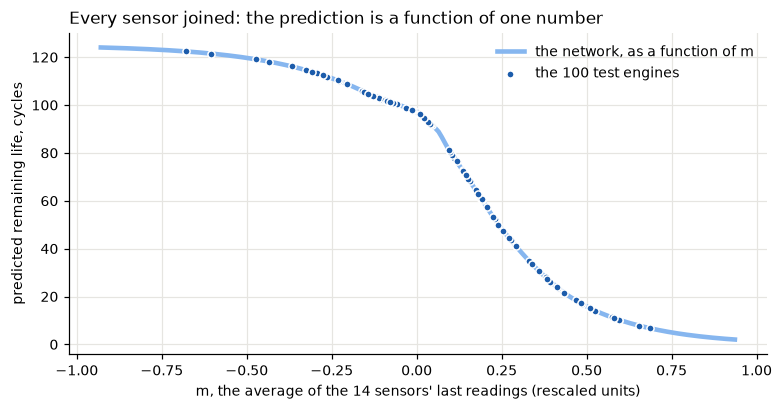

In [8]:
# The network's whole response: windows whose 14 last readings all equal m.
sweep = np.linspace(averages.min() - 0.25, averages.max() + 0.25, 200)
probe = np.repeat(test_windows[:1], len(sweep), axis=0)
probe[:, :, -1] = sweep[:, None]
curve = predict(probe)
falls_throughout = bool(np.all(np.diff(curve) <= 0))
print(f"The curve never rises as m rises: {falls_throughout}")

figure, axis = plt.subplots(figsize=(7.2, 3.8))
axis.plot(sweep, curve, color="#86b6ef", linewidth=3, label="the network, as a function of m")
axis.scatter(averages, as_given, s=22, color="#1c5cab", edgecolor="white", linewidth=1,
             zorder=3, label="the 100 test engines")
axis.set_xlabel("m, the average of the 14 sensors' last readings (rescaled units)")
axis.set_ylabel("predicted remaining life, cycles")
axis.set_title("Every sensor joined: the prediction is a function of one number", loc="left")
axis.grid(color="#e6e5e1", linewidth=0.8)
axis.spines[["top", "right"]].set_visible(False)
axis.legend(frameon=False)
plt.tight_layout()
plt.show()

Every test engine sits on the curve: once its 14 last readings are averaged, nothing else about them reaches the prediction. The readings were rescaled so that each sensor averages 0 over the training engines' rows, and so `m` does too; over the whole range drawn, the predicted life only falls as `m` rises.

So, in this network, joining every sensor to every other does not merely remove the paper's knowledge of which sensors are related. It leaves the network one number to predict from where the paper's graph leaves it nine different rows. `04_comparison_fd001.ipynb` measures what that costs.

Two conditions make it this extreme, and both are true of every run in this folder:

- **Each row is divided by its total.** This one turns out not to matter: step 3 found that the other rescaling the paper's wording allows gives the same table here, because every sensor has the same 13 neighbours, so both formulas put 1/14 in every cell.
- **Each sensor carries one number in, and it is a reading.** With the paper's recurrent stage, each sensor's number would come from a network of its own reading that sensor's 30 cycles, so the 14 numbers being averaged would already be weighted differently, sensor by sensor, by training. The averaging would still happen, but what is averaged would be learned. A stored run measures it: the study of one setting at a time trained this graph and the paper's with the recurrent stage, five seeds each, at commit `fd65a3b-dirty` (finding F-19), and there joining every sensor cost 0.402 cycles of test RMSE (*p* = 0.372) and 0.112 cycles of held-back RMSE as recorded (*p* = 0.221), neither distinguishable from the seed-to-seed spread. Those runs keep the parameters of the pass that did best on the held-back engines, and for the recurrent stage that one choice changes what the stage is worth (finding F-16). `04_comparison_fd001.ipynb` prints them in its step 6.

(Corrected 2026-10-02, before this notebook was first committed: this bullet said no run of the recurrent-stage version was stored. A review the same day found the study's runs, which `docs/ASSUMPTIONS.md` already quoted under finding F-04.)

### Step 6 — Read the stored result

**What.** The scores of all five seeds of the run, on the four measures notebook 02's step 11 defines, and the error on each seed's held-back engines.

**Why.** One seed is not a result (working rule 3).

**Check.** The means and spreads computed here must agree with the run's own `summary.json`.

In [9]:
results = run.results.set_index("seed")
columns = {
    "rmse": "test RMSE", "score": "test NASA score", "r2": "test R-squared",
    "asue": "test ASUE", "validation_rmse": "held-back RMSE", "best_epoch": "pass kept",
}
per_seed = results[list(columns)].rename(columns=columns)
measures = list(columns.values())[:5]
shown = per_seed.astype(object)
for m in measures:
    shown[m] = [f"{value:.3f}" for value in per_seed[m]]
shown.loc["mean ± standard deviation"] = (
    [f"{per_seed[m].mean():.3f} ± {per_seed[m].std(ddof=1):.3f}" for m in measures] + [""]
)
print(f"Run    : {run.name}")
print(f"Commit : {run.summary['commit']}, finished {run.summary['finished_utc']} (UTC)\n")
display(shown)

# The run wrote its own mean and spread into summary.json; they must agree.
matches_summary = all(
    np.isclose(results[m].mean(), run.summary["mean"][m])
    and np.isclose(results[m].std(ddof=1), run.summary["std"][m])
    for m in ("rmse", "score", "r2", "asue")
)
assert matches_summary
print("OK  The means and spreads agree with the run's own summary.json.")

Run    : fd001_complete_row_cap_5seed_varsplit_cfgf21547_f386291-dirty_20260914T150527Z
Commit : f386291-dirty, finished 20260914T150527Z (UTC)



,test RMSE,test NASA score,test R-squared,test ASUE,held-back RMSE,pass kept
seed,,,,,,
42,18.820,723.413,0.779,14.063,22.700,31
43,18.953,761.390,0.776,13.124,21.874,23
44,19.840,913.454,0.755,13.520,22.623,38
45,19.607,838.662,0.761,13.697,23.559,18
46,19.185,743.491,0.771,14.391,22.318,40
mean ± standard deviation,19.281 ± 0.432,796.082 ± 78.802,0.768 ± 0.010,13.759 ± 0.489,22.615 ± 0.620,


OK  The means and spreads agree with the run's own summary.json.


**No published figure matches this configuration.** The paper's "ESTGNN w/o Physics prior" row, 12.34 on FD001 in its Table 11, is its full network, with the recurrent stage, and with a replacement for its graph it never describes. These runs have no recurrent stage. The only fair comparison for them is the paper's graph under exactly the same configuration, which `04_comparison_fd001.ipynb` makes.

## 6. Final verification

Every check in this notebook, in one place.

In [10]:
checks = [
    ("The loaded network scores what the run recorded", same_network, f"seed {SEED}"),
    ("The network's graph is the rebuilt data's", same_graph, run.summary["commit"]),
    ("Every pair of sensors is joined", every_pair_joined, f"{report['n_edges']} edges"),
    ("The rescaled table holds only 1/14", one_value, f"{np.unique(a_hat)[0]:.6f}"),
    ("The rescaled table is normalize_adjacency's", matches_function, 'method="row"'),
    ("One graph layer by hand equals the network's", layer_matches, "1 distinct row out"),
    ("Same average of last readings, same prediction", same_average_same_prediction,
     "T24 +1, T30 -1"),
    ("A different average moves the prediction", average_moves_prediction, "T24 +1"),
    ("The other rescaling gives the same table", same_under_symmetric, 'method="symmetric"'),
    ("The average alone decides, on 100 test engines", one_number_decides,
     f"largest change {largest_change:.1e} cycles"),
    ("Five-seed means agree with summary.json", matches_summary, run.name[:40] + "..."),
]

width = max(len(name) for name, _, _ in checks) + 2
print(f"{'CHECK':<{width}} RESULT   DETAIL")
print("-" * (width + 40))
for name, passed, detail in checks:
    print(f"{name:<{width}} {'PASS' if passed else 'FAIL':<8} {detail}")
print("-" * (width + 40))
failed = [name for name, passed, _ in checks if not passed]
if failed:
    raise AssertionError(f"{len(failed)} check(s) failed: {failed}")
print(f"All {len(checks)} checks passed.")

CHECK                                             RESULT   DETAIL
-----------------------------------------------------------------------------------------
The loaded network scores what the run recorded   PASS     seed 42
The network's graph is the rebuilt data's         PASS     f386291-dirty
Every pair of sensors is joined                   PASS     91 edges
The rescaled table holds only 1/14                PASS     0.071429
The rescaled table is normalize_adjacency's       PASS     method="row"
One graph layer by hand equals the network's      PASS     1 distinct row out
Same average of last readings, same prediction    PASS     T24 +1, T30 -1
A different average moves the prediction          PASS     T24 +1
The other rescaling gives the same table          PASS     method="symmetric"
The average alone decides, on 100 test engines    PASS     largest change 2.5e-05 cycles
Five-seed means agree with summary.json           PASS     fd001_complete_row_cap_5seed_varsplit_cf...
--------

## 7. Summary

### What this notebook produced

- **The every-sensor-joined graph, as the stored network received it**: 91 edges, and a rescaled table holding 1/14 in every cell.
- **One graph layer worked by hand** on the first test engine's window, ending in 14 identical rows.
- **The finding that this network predicts from one number**, the average of the 14 sensors' last readings: shown by argument in the background, and measured on the trained network over the 100 test engines.
- **The stored five-seed result** of the network trained on this graph, with the commit that produced it.

### Decisions that were not read from the paper

| Decision | Value used | Written up as |
|---|---|---|
| What replaces the paper's graph in "without physics prior" | Every sensor joined to every other | A-19 |
| How the table is rescaled | Each row of `A + I` divided by its own total; here the other formula gives the same table | A-21 |
| What a sensor carries into the graph layers | The last reading of its window, one number | A-07 |
| Held-back engines and the parameters kept | 20 % of the training engines; the parameters of the pass that did best on them | A-06 |

### References

- Wen, J.-R., et al. (2026). Explainable spatiotemporal graph neutral network with dynamic SHAP enhancement for aeroengine RUL prediction. *Aerospace Science and Technology*, 168, 110875.

Full citations are in `docs/REFERENCES.md`.